# Component 3 — DDK Speech-Motor Detection

This notebook trains and evaluates an independent Component 3 baseline on
repeated-syllable DDK recordings from the Italian Parkinson's Voice and
Speech dataset. It is deliberately separate from Component 2: the model
uses speech-motor timing and articulation features, not phonation features.

The notebook:

- discovers an already-extracted dataset directory (it does not require the
  ZIP-only production loader);
- excludes the Young Healthy Control group, matching the existing loader;
- preserves participant boundaries during evaluation;
- reuses `component3_ddk.features.extract_ddk_features`;
- evaluates a Random Forest baseline and compares D1 (`pa`) with D2 (`ta`);
- writes outputs to stable, designated paths and overwrites those specific latest-run artifacts.

**Research note:** Any metrics printed below are calculated only after the
notebook is executed on the available local dataset. No results are
hard-coded in this notebook.

## 1. Environment and project configuration

Run this notebook with the repository's existing Python/Jupyter kernel.
It does not create an environment or install packages.

In [1]:
from pathlib import Path
import json
import os
import re
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REQUIRED_IMPORTS = [
    "librosa", "soundfile", "sklearn", "joblib",
]
missing_imports = []
for module_name in REQUIRED_IMPORTS:
    try:
        __import__(module_name)
    except ImportError:
        missing_imports.append(module_name)
if missing_imports:
    raise ImportError(
        "Missing packages in the selected Jupyter kernel: "
        + ", ".join(missing_imports)
        + ". Install them in the chosen environment only after confirming "
          "with the project owner."
    )

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for candidate in candidates:
        if (candidate / "component3_ddk").is_dir() and (candidate / "common").is_dir():
            return candidate
        nested = candidate / "parkinson-speech-ai"
        if (nested / "component3_ddk").is_dir() and (nested / "common").is_dir():
            return nested
    raise FileNotFoundError(
        "Could not locate parkinson-speech-ai. Open this notebook from the "
        "repository or update the project-root detection."
    )

REPO_ROOT = find_project_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

DATA_ROOT = REPO_ROOT / "data"
EXTRACTED_DATASET = DATA_ROOT / "Italian Parkinson_s Voice and speech"
RESULTS_DIR = REPO_ROOT / "results" / "component3_ddk"
MODELS_DIR = REPO_ROOT / "models"

print("Project root:", REPO_ROOT)
print("Expected extracted dataset:", EXTRACTED_DATASET)
print("Python:", sys.executable)
print("Python version:", sys.version.split()[0])

Project root: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai
Expected extracted dataset: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\data\Italian Parkinson_s Voice and speech
Python: c:\Users\prasadxma\anaconda3\python.exe
Python version: 3.14.6


## 2. Dataset discovery and validation

The existing `italian_ddk_dataset.py` expects
`data/italian_pvs/italian_pvs.zip`. This notebook instead searches the
extracted directory requested for this project. It accepts the exact
directory name and a small number of safe alternatives, but never silently
falls back to another dataset.

In [2]:
GROUP_LABELS = {
    "22 Elderly Healthy Control": 0,
    "28 People with Parkinson's disease": 1,
}
EXCLUDED_GROUP = "15 Young Healthy Control"
expected_groups = set(GROUP_LABELS) | {EXCLUDED_GROUP}

dataset_candidates = [
    EXTRACTED_DATASET,
    DATA_ROOT / "Italian Parkinson_s Voice and speech",
    DATA_ROOT / "raw" / "Italian Parkinson_s Voice and speech",
    DATA_ROOT / "raw" / "Italian Parkinson's Voice and speech",
]
DATASET_ROOT = next((path for path in dataset_candidates if path.is_dir()), None)
if DATASET_ROOT is None:
    raise FileNotFoundError(
        "Extracted dataset directory not found. Copy the dataset to:\n"
        f"  {EXTRACTED_DATASET}\n"
        "The notebook does not extract the ZIP or modify the source loader."
    )

group_dirs = {path.name: path for path in DATASET_ROOT.iterdir() if path.is_dir()}
print("Dataset root:", DATASET_ROOT)
print("Discovered groups:", sorted(group_dirs))
missing_groups = set(GROUP_LABELS) - set(group_dirs)
if missing_groups:
    raise FileNotFoundError(f"Required groups are missing: {sorted(missing_groups)}")

wav_paths = sorted(
    path for path in DATASET_ROOT.rglob("*")
    if path.is_file()
    and path.suffix.lower() == ".wav"
    and path.name.upper().startswith(("D1", "D2"))
)
if not wav_paths:
    raise FileNotFoundError("No D1/D2 WAV recordings were found under the dataset root.")

def group_for_path(path):
    relative_parts = path.relative_to(DATASET_ROOT).parts
    for group_name in expected_groups:
        if group_name in relative_parts:
            return group_name
    return None

discovery_rows = []
for path in wav_paths:
    group = group_for_path(path)
    if group is None:
        continue
    task = "D1" if path.name.upper().startswith("D1") else "D2"
    discovery_rows.append({
        "path": path,
        "relative_path": str(path.relative_to(DATASET_ROOT)),
        "group": group,
        "task": task,
        "syllable": "pa" if task == "D1" else "ta",
        "included": group in GROUP_LABELS,
    })
discovery_df = pd.DataFrame(discovery_rows)
if discovery_df.empty:
    raise ValueError("No D1/D2 files were found in the expected dataset groups.")

print("\nAll discovered recordings by group/task:")
display(discovery_df.groupby(["group", "task"]).size().unstack(fill_value=0))
print("\nRecordings used for modelling:")
display(discovery_df[discovery_df["included"]].groupby(["group", "task"]).size().unstack(fill_value=0))
print(f"Excluded young-control recordings: {(~discovery_df['included']).sum()}")

Dataset root: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\data\Italian Parkinson_s Voice and speech
Discovered groups: ['15 Young Healthy Control', '22 Elderly Healthy Control', "28 People with Parkinson's disease"]

All discovered recordings by group/task:


task,D1,D2
group,,
22 Elderly Healthy Control,22,22
28 People with Parkinson's disease,28,28



Recordings used for modelling:


task,D1,D2
group,,
22 Elderly Healthy Control,22,22
28 People with Parkinson's disease,28,28


Excluded young-control recordings: 0


## 3. Participant identities and labels

The original loader uses the participant folder immediately containing each WAV.
In this extracted layout, PD recordings can be nested as `PD group / numbered
range / participant / recording`. Because participant folder names can repeat
across numbered ranges, the PD range is part of the participant ID. Elderly HC
recordings use `HC group / participant / recording`.

This conservative rule never merges same-name folders from different PD ranges,
and keeps D1 and D2 from the same participant in one group. The notebook reports
repeated folder names and unique participant counts before splitting.

In [3]:
GROUP_LABELS = {
    "22 Elderly Healthy Control": 0,
    "28 People with Parkinson's disease": 1,
}
EXCLUDED_GROUP = "15 Young Healthy Control"
PD_RANGE_RE = re.compile(r"^\d+[-_]\d+$")

def participant_metadata(path, group):
    participant_folder = path.parent.name
    parent_folder = path.parent.parent.name
    if group == "28 People with Parkinson's disease" and PD_RANGE_RE.match(parent_folder):
        identity_scope = parent_folder
        participant_id = f"ITA_PD_{identity_scope}_{participant_folder}"
    else:
        identity_scope = group
        participant_id = f"ITA_HC_{participant_folder}"
    return participant_folder, identity_scope, participant_id

model_df = discovery_df[discovery_df["included"]].copy()
metadata = [participant_metadata(path, group) for path, group in zip(model_df["path"], model_df["group"])]
model_df[["participant_folder", "identity_scope", "participant_id"]] = pd.DataFrame(metadata, index=model_df.index)
model_df["label"] = model_df["group"].map(GROUP_LABELS).astype(int)
model_df["label_name"] = model_df["label"].map({0: "HC", 1: "PD"})

display(model_df[["relative_path", "group", "identity_scope", "participant_folder", "participant_id", "task", "label_name"]].head())
repeated = model_df.groupby(["group", "participant_folder"])["identity_scope"].nunique().reset_index(name="identity_scope_count")
repeated = repeated[repeated["identity_scope_count"] > 1]
print("Repeated participant-folder names across identity scopes:")
display(repeated if not repeated.empty else pd.DataFrame({"status": ["None found"]}))
participant_table = model_df[["participant_id", "label", "label_name", "group"]].drop_duplicates("participant_id").sort_values("participant_id").reset_index(drop=True)
print("Unique participants by group and label:")
display(participant_table.groupby(["label_name", "group"]).size().rename("participants").reset_index())
print("Total unique participants:", participant_table["participant_id"].nunique())

,relative_path,group,identity_scope,participant_folder,participant_id,task,label_name
0,22 Elderly Healthy Control\AGNESE P\D1APGANRET...,22 Elderly Healthy Control,22 Elderly Healthy Control,AGNESE P,ITA_HC_AGNESE P,D1,HC
1,22 Elderly Healthy Control\AGNESE P\D2APGANRET...,22 Elderly Healthy Control,22 Elderly Healthy Control,AGNESE P,ITA_HC_AGNESE P,D2,HC
2,22 Elderly Healthy Control\ANGELA C\D1ACNAGRER...,22 Elderly Healthy Control,22 Elderly Healthy Control,ANGELA C,ITA_HC_ANGELA C,D1,HC
3,22 Elderly Healthy Control\ANGELA C\D2ACNAGRER...,22 Elderly Healthy Control,22 Elderly Healthy Control,ANGELA C,ITA_HC_ANGELA C,D2,HC
4,22 Elderly Healthy Control\ANGELA G\D1AGNIGNEE...,22 Elderly Healthy Control,22 Elderly Healthy Control,ANGELA G,ITA_HC_ANGELA G,D1,HC


Repeated participant-folder names across identity scopes:


,group,participant_folder,identity_scope_count
38,28 People with Parkinson's disease,Nicola S,2
41,28 People with Parkinson's disease,Roberto R,2
45,28 People with Parkinson's disease,Vito S,3


Unique participants by group and label:


,label_name,group,participants
0,HC,22 Elderly Healthy Control,22
1,PD,28 People with Parkinson's disease,28


Total unique participants: 50


## 4. Official metadata review and identity limitation

The extracted dataset contains official spreadsheet files (`FILE CODES.xlsx`, `Tab 3.xlsx`, and `TAB 5.xlsx`) alongside the recordings. This notebook inventories their filenames and sizes only; listing these files does not prove that they contain a participant mapping. Because their contents are not parsed here, a verified cross-range participant identity mapping has not been established. The conservative structural ID (numbered PD range plus folder) is therefore retained, and unresolved identity risk is reported rather than silently merged or separated.

In [4]:
metadata_files = sorted(DATASET_ROOT.rglob("*.xlsx"))
metadata_inventory = pd.DataFrame({
    "metadata_file": [str(path.relative_to(DATASET_ROOT)) for path in metadata_files],
    "size_bytes": [path.stat().st_size for path in metadata_files],
})
print("Official metadata files found:", len(metadata_inventory))
display(metadata_inventory)
print(
    "Identity decision: spreadsheet filenames and sizes were inventoried, but "
    "their contents were not parsed; no verified cross-range participant mapping "
    "has been established. No automated merge is made from repeated names."
)
identity_review = {
    "metadata_files_found": metadata_inventory["metadata_file"].tolist(),
    "metadata_contents_inspected_for_identity": False,
    "authoritative_cross_range_key_verified": False,
    "unresolved_risk": "Spreadsheet inventory alone does not establish whether repeated folder names identify the same person across PD ranges.",
    "id_rule": "PD numbered range plus participant folder; HC group plus participant folder",
}


Official metadata files found: 6


,metadata_file,size_bytes
0,15 Young Healthy Control\15 YHC.xlsx,11940
1,15 Young Healthy Control\FILE CODES.xlsx,26129
2,22 Elderly Healthy Control\FILE CODES.xlsx,26129
3,22 Elderly Healthy Control\Tab 3.xlsx,40569
4,28 People with Parkinson's disease\FILE CODES....,26129
5,28 People with Parkinson's disease\TAB 5.xlsx,13799


Identity decision: spreadsheet filenames and sizes were inventoried, but their contents were not parsed; no verified cross-range participant mapping has been established. No automated merge is made from repeated names.


## 4. Audio inspection

The first available recording is inspected for duration, sample rate, and
waveform. This is a sanity check only; feature extraction below uses the
shared Component 3 implementation.

Inspection file: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\data\Italian Parkinson_s Voice and speech\22 Elderly Healthy Control\AGNESE P\D1APGANRET55F170320171106.wav
Duration (seconds): 6.784
Sample rate: 16000
Samples: 108544


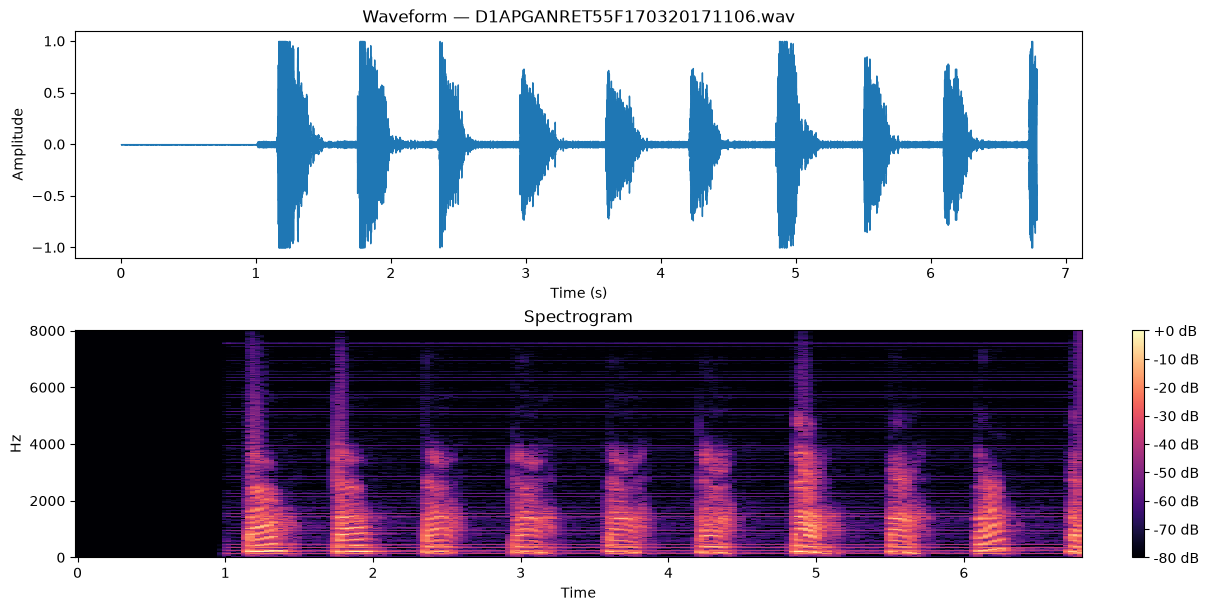

In [5]:
import librosa
import librosa.display
import soundfile as sf

inspection_path = model_df.iloc[0]["path"]
signal, sample_rate = librosa.load(inspection_path, sr=None, mono=True)
print("Inspection file:", inspection_path)
print("Duration (seconds):", round(len(signal) / sample_rate, 3))
print("Sample rate:", sample_rate)
print("Samples:", len(signal))

fig, axes = plt.subplots(2, 1, figsize=(12, 6), constrained_layout=True)
librosa.display.waveshow(signal, sr=sample_rate, ax=axes[0])
axes[0].set_title(f"Waveform — {inspection_path.name}")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
spectrogram = librosa.amplitude_to_db(
    np.abs(librosa.stft(signal)), ref=np.max
)
librosa.display.specshow(
    spectrogram, sr=sample_rate, x_axis="time", y_axis="hz", ax=axes[1]
)
axes[1].set_title("Spectrogram")
fig.colorbar(axes[1].collections[0], ax=axes[1], format="%+2.0f dB")
plt.show()

## 5. DDK feature extraction

The notebook reuses `component3_ddk.features.extract_ddk_features` and its
`FEATURE_NAMES` list. The extractor provides 12 features covering rate,
inter-onset timing, pauses, spectral measures, and MFCC articulation
measures. Extraction failures and recordings with too few detected onsets
are retained in a report and excluded from modelling.

In [6]:
# The shared audio utility imports imageio_ffmpeg for non-WAV conversion.
# This dataset is already WAV, so keep the shared feature extractor usable
# without requiring that optional converter dependency in this notebook.
from pathlib import Path
import sys
import types

try:
    import imageio_ffmpeg  # noqa: F401
except ModuleNotFoundError as exc:
    if exc.name != "imageio_ffmpeg":
        raise
    audio_io_fallback = types.ModuleType("common.audio_io")
    def ensure_wav(audio_path):
        if Path(audio_path).suffix.lower() != ".wav":
            raise RuntimeError(
                "This notebook fallback supports WAV files only. Install "
                "imageio-ffmpeg to process non-WAV recordings."
            )
        return audio_path
    audio_io_fallback.ensure_wav = ensure_wav
    sys.modules["common.audio_io"] = audio_io_fallback
    print("imageio-ffmpeg is unavailable; using the WAV-only notebook fallback.")

from component3_ddk.features import FEATURE_NAMES, extract_ddk_features

extraction_rows = []
failures = []
for row in model_df.itertuples(index=False):
    try:
        features = extract_ddk_features(str(row.path))
        if features is None:
            failures.append({
                "relative_path": row.relative_path,
                "reason": "Too few detected syllable onsets",
            })
            continue
        record = {name: features[name] for name in FEATURE_NAMES}
        record.update({
            "filename": row.relative_path,
            "participant_id": row.participant_id,
            "task": row.task,
            "syllable": row.syllable,
            "label": int(row.label),
            "label_name": row.label_name,
            "group": row.group,
        })
        extraction_rows.append(record)
    except Exception as exc:
        failures.append({
            "relative_path": row.relative_path,
            "reason": f"{type(exc).__name__}: {exc}",
        })

features_df = pd.DataFrame(extraction_rows)
failure_df = pd.DataFrame(failures)
if features_df.empty:
    raise RuntimeError("No recordings produced usable DDK features.")
print("Feature rows:", len(features_df))
print("Failures/skips:", len(failure_df))
if not failure_df.empty:
    display(failure_df.head(20))
display(features_df.groupby(["label_name", "task"]).size().unstack(fill_value=0))

imageio-ffmpeg is unavailable; using the WAV-only notebook fallback.
Feature rows: 100
Failures/skips: 0


task,D1,D2
label_name,,
HC,22,22
PD,28,28


## 6. Feature dataset and exploratory analysis

## 7. Audio provenance and duplicate checks

Every included WAV is passed to the extractor during this ordered run; no feature CSV or saved model is read. File hashes identify byte-for-byte duplicates under different paths. A matching hash is reported and not silently removed, because duplicate recordings require a research decision before modelling.

In [7]:
import hashlib

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

hash_rows = []
for row in model_df.itertuples(index=False):
    hash_rows.append({"relative_path": row.relative_path, "sha256": sha256_file(row.path)})
content_hash_df = pd.DataFrame(hash_rows)
duplicate_hashes = content_hash_df[content_hash_df.duplicated("sha256", keep=False)].sort_values("sha256")
print("Byte-identical duplicate groups:", duplicate_hashes["sha256"].nunique())
if duplicate_hashes.empty:
    print("No byte-identical duplicates found among included recordings.")
else:
    display(duplicate_hashes)

Byte-identical duplicate groups: 0
No byte-identical duplicates found among included recordings.


,count,mean,std,min,25%,50%,75%,max
ddk_rate,100.0,2.804788,1.053543,0.921659,2.023737,2.739286,3.401995,5.688889
mean_ioi,100.0,0.373993,0.174384,0.148000,0.260800,0.321684,0.436349,1.049542
std_ioi,100.0,0.298800,0.113395,0.016251,0.244321,0.289326,0.352127,0.603563
cv_ioi,100.0,0.891650,0.279395,0.021393,0.836776,0.956029,1.054928,1.427216
num_pauses,100.0,6.820000,1.950809,3.000000,5.000000,7.000000,8.000000,13.000000
pause_ratio,100.0,0.367917,0.146892,0.062578,0.265956,0.377926,0.466660,0.673281
mean_spectral_centroid,100.0,2142.794491,1259.972151,895.457949,1451.067010,1631.835320,2015.097271,5993.294485
std_spectral_centroid,100.0,1101.955061,1050.080081,178.072808,536.193317,634.068911,916.723461,3817.332499
mean_spectral_bandwidth,100.0,2212.491763,1267.313986,1136.660158,1491.394147,1635.529741,1973.001674,5337.904541
mean_mfcc1,100.0,87.575554,23.962500,29.353926,71.314106,89.216702,105.360521,136.718521


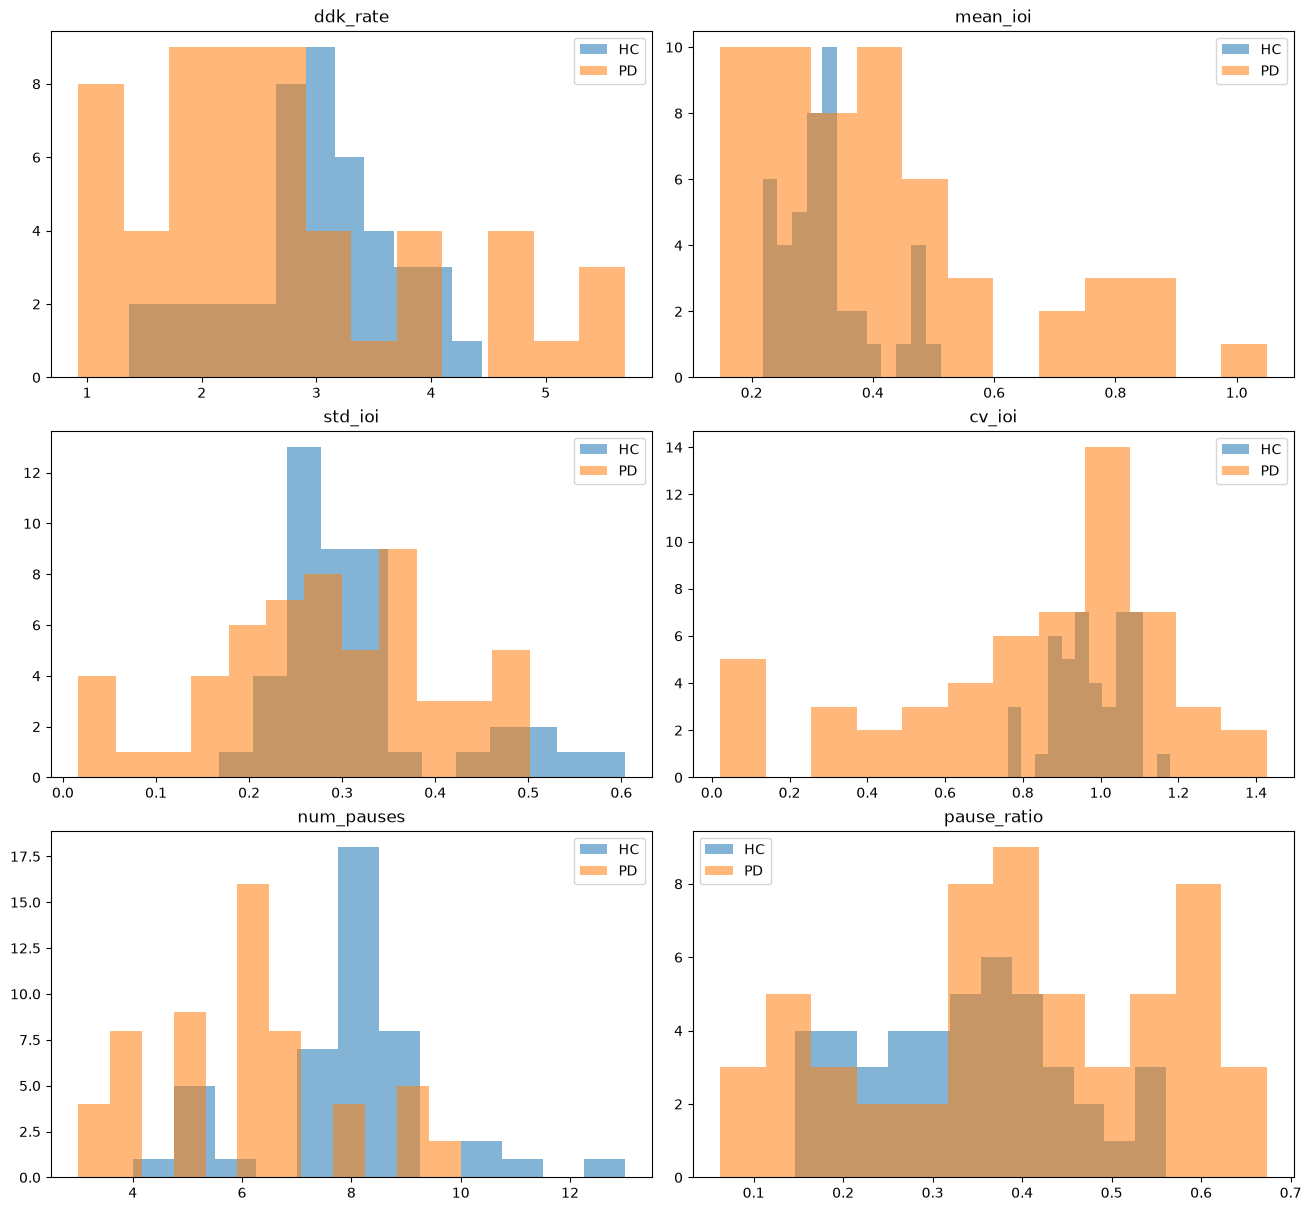

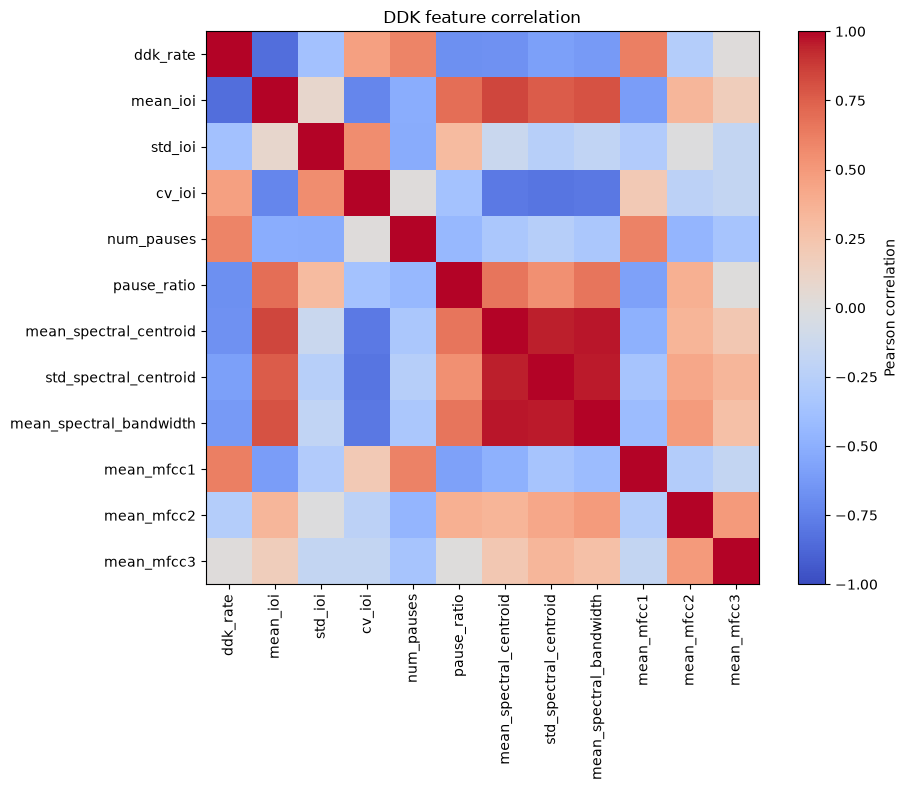

In [8]:
display(features_df[FEATURE_NAMES].describe().T)

fig, axes = plt.subplots(3, 2, figsize=(13, 12), constrained_layout=True)
for axis, feature in zip(axes.flat, FEATURE_NAMES[:6]):
    for label_name, subset in features_df.groupby("label_name"):
        axis.hist(subset[feature].dropna(), alpha=0.55, bins=12, label=label_name)
    axis.set_title(feature)
    axis.legend()
plt.show()

correlation = features_df[FEATURE_NAMES].corr()
plt.figure(figsize=(10, 8))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, rotation=90)
plt.yticks(range(len(FEATURE_NAMES)), FEATURE_NAMES)
plt.title("DDK feature correlation")
plt.tight_layout()
plt.show()

## 7. Missing values and preprocessing

The baseline extractor should return finite numeric values. This cell
verifies that assumption explicitly. Rows with non-finite feature values
are excluded and reported rather than silently imputed. Scaling is included
inside the SVM/logistic pipelines; Random Forest does not require scaling.

In [9]:
missing_counts = features_df[FEATURE_NAMES].isna().sum()
nonfinite_counts = (~np.isfinite(features_df[FEATURE_NAMES])).sum()
print("Missing values:")
display(missing_counts[missing_counts > 0])
print("Non-finite values:")
display(nonfinite_counts[nonfinite_counts > 0])

valid_mask = (
    features_df[FEATURE_NAMES].notna().all(axis=1)
    & np.isfinite(features_df[FEATURE_NAMES]).all(axis=1)
)
invalid_feature_rows = features_df.loc[~valid_mask].copy()
if not invalid_feature_rows.empty:
    print("Dropping invalid feature rows:", len(invalid_feature_rows))
analysis_df = features_df.loc[valid_mask].reset_index(drop=True)
if analysis_df["label"].nunique() < 2:
    raise ValueError("Both HC and PD labels are required for evaluation.")

Missing values:


Series([], dtype: int64)

Non-finite values:


Series([], dtype: int64)

## 7. Participant-level train/test split

The held-out test set is created from unique participants, not WAV rows. A fixed
seed and stratification by HC/PD are used where class counts permit. All
recordings from a participant, including D1 and D2, remain in one split.

In [10]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TEST_SIZE = 0.20

participant_table = (
    analysis_df[["participant_id", "label", "label_name", "group"]]
    .drop_duplicates("participant_id")
    .sort_values("participant_id")
    .reset_index(drop=True)
)
if participant_table["label"].nunique() < 2:
    raise ValueError("Both HC and PD participants are required for a participant-level split.")

try:
    train_ids, test_ids = train_test_split(
        participant_table["participant_id"],
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=participant_table["label"],
    )
except ValueError as exc:
    warnings.warn(f"Stratified split unavailable ({exc}); using seeded unstratified split.")
    train_ids, test_ids = train_test_split(
        participant_table["participant_id"],
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
    )

train_participants, test_participants = set(train_ids), set(test_ids)
if train_participants & test_participants:
    raise AssertionError("Participant leakage detected between train and test splits.")

analysis_df["split"] = np.where(
    analysis_df["participant_id"].isin(train_participants), "train", "test"
)
train_df = analysis_df[analysis_df["split"] == "train"].copy()
test_df = analysis_df[analysis_df["split"] == "test"].copy()

print("Participant overlap between train and test:", train_participants & test_participants)
print("Training participants:", len(train_participants), "| Test participants:", len(test_participants))
split_summary = (
    analysis_df.groupby(["split", "label_name", "task"])
    .agg(recordings=("filename", "size"), participants=("participant_id", "nunique"))
    .reset_index()
)
display(split_summary)
display(
    participant_table.assign(
        split=participant_table["participant_id"].map(
            lambda value: "train" if value in train_participants else "test"
        )
    )
)

Participant overlap between train and test: set()
Training participants: 40 | Test participants: 10


,split,label_name,task,recordings,participants
0,test,HC,D1,4,4
1,test,HC,D2,4,4
2,test,PD,D1,6,6
3,test,PD,D2,6,6
4,train,HC,D1,18,18
5,train,HC,D2,18,18
6,train,PD,D1,22,22
7,train,PD,D2,22,22


,participant_id,label,label_name,group,split
0,ITA_HC_AGNESE P,0,HC,22 Elderly Healthy Control,train
1,ITA_HC_ANGELA C,0,HC,22 Elderly Healthy Control,train
2,ITA_HC_ANGELA G,0,HC,22 Elderly Healthy Control,train
3,ITA_HC_ANTONIETTA P,0,HC,22 Elderly Healthy Control,train
4,ITA_HC_ANTONIO C,0,HC,22 Elderly Healthy Control,train
5,ITA_HC_BRIGIDA C,0,HC,22 Elderly Healthy Control,train
6,ITA_HC_GILDA C,0,HC,22 Elderly Healthy Control,test
7,ITA_HC_GIOVANNA G,0,HC,22 Elderly Healthy Control,train
8,ITA_HC_GIOVANNI B,0,HC,22 Elderly Healthy Control,train
9,ITA_HC_GRAZIA G,0,HC,22 Elderly Healthy Control,train


## 8. Model training and training-only cross-validation

The primary model is a balanced Random Forest using the existing 12 DDK
features. Logistic Regression and SVM are comparison experiments on the same
participant split. Any cross-validation below uses training participants only;
the held-out test set is not used for selection or tuning.

In [11]:
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support, roc_auc_score, RocCurveDisplay
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X_train, y_train = train_df[FEATURE_NAMES], train_df["label"]
X_test, y_test = test_df[FEATURE_NAMES], test_df["label"]
groups_train = train_df["participant_id"]
candidates = {
    "random_forest": RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, class_weight="balanced"),
    "svm_rbf": Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=RANDOM_STATE))]),
    "logistic_regression": Pipeline([("scaler", StandardScaler()), ("logistic", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))]),
}

# Stability is assessed only within the development participants. The held-out
# test set is never passed to CV, configuration checks, or model selection.
training_cv_summary = {}
cv_repetitions = 3
cv_splits = 0
cv_skip_reasons = []
min_class_participants = int(train_df.groupby("label")["participant_id"].nunique().min())
if min_class_participants >= 2 and train_df["participant_id"].nunique() >= 4:
    candidate_splits = min(5, min_class_participants)
    validated_fold_sets = []
    for repetition in range(cv_repetitions):
        cv = StratifiedGroupKFold(
            n_splits=candidate_splits,
            shuffle=True,
            random_state=RANDOM_STATE + repetition,
        )
        fold_pairs = list(cv.split(X_train, y_train, groups_train))
        invalid_folds = []
        for fold_number, (train_indices, validation_indices) in enumerate(fold_pairs, start=1):
            train_classes = set(y_train.iloc[train_indices].unique())
            validation_classes = set(y_train.iloc[validation_indices].unique())
            train_groups = set(groups_train.iloc[train_indices])
            validation_groups = set(groups_train.iloc[validation_indices])
            if train_classes != {0, 1} or validation_classes != {0, 1}:
                invalid_folds.append(
                    f"repetition {repetition + 1} fold {fold_number}: "
                    f"training classes={sorted(train_classes)}, "
                    f"validation classes={sorted(validation_classes)}"
                )
            if train_groups & validation_groups:
                invalid_folds.append(
                    f"repetition {repetition + 1} fold {fold_number}: participant overlap"
                )
        if invalid_folds:
            cv_skip_reasons.extend(invalid_folds)
        else:
            validated_fold_sets.append(fold_pairs)

    if len(validated_fold_sets) == cv_repetitions:
        repeated_scores = {name: [] for name in candidates}
        for repetition, fold_pairs in enumerate(validated_fold_sets):
            for name, estimator in candidates.items():
                scores = cross_val_score(
                    estimator,
                    X_train,
                    y_train,
                    groups=groups_train,
                    cv=fold_pairs,
                    scoring="accuracy",
                )
                repeated_scores[name].extend(float(score) for score in scores)
        cv_splits = candidate_splits
        for name, scores in repeated_scores.items():
            training_cv_summary[name] = {
                "fold_accuracies": scores,
                "mean_accuracy": float(np.mean(scores)),
                "std_accuracy": float(np.std(scores)),
                "repetitions": cv_repetitions,
                "folds_per_repetition": cv_splits,
                "fold_validation_checked": True,
            }
        display(pd.DataFrame(training_cv_summary).T)
    else:
        cv_skip_reasons.insert(
            0,
            "At least one generated grouped fold lacked both classes in its "
            "training or validation subset, or had participant overlap.",
        )
else:
    cv_skip_reasons.append(
        "Insufficient training participants: at least two participants per "
        "class and four total participants are required before grouped CV "
        "fold construction."
    )

if cv_splits == 0:
    training_cv_summary = {
        "status": "skipped",
        "reason": cv_skip_reasons,
        "repetitions_requested": cv_repetitions,
        "fold_validation_checked": False,
    }
    print("Training-only repeated grouped CV skipped:")
    for reason in cv_skip_reasons:
        print(" -", reason)

primary_model = candidates["random_forest"]
primary_model.fit(X_train, y_train)
print("Primary model fitted on training recordings:", len(train_df))


c:\Users\prasadxma\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\prasadxma\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\prasadxma\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\prasadxma\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in ve

,fold_accuracies,mean_accuracy,std_accuracy,repetitions,folds_per_repetition,fold_validation_checked
random_forest,"[0.875, 0.9375, 0.875, 0.9375, 1.0, 0.8125, 0....",0.941667,0.058035,3,5,True
svm_rbf,"[0.875, 0.9375, 0.9375, 1.0, 1.0, 0.8125, 1.0,...",0.9625,0.059512,3,5,True
logistic_regression,"[0.875, 0.9375, 1.0, 1.0, 1.0, 0.8125, 1.0, 1....",0.9625,0.0677,3,5,True


Primary model fitted on training recordings: 80


Declared aggregation: mean available D1/D2 PD probabilities; one-task participants use the available task.


,evaluation,participants,recordings,accuracy,precision_PD,sensitivity_recall_PD,specificity_HC,f1_PD,roc_auc
0,held_out_test_recording,10,20,1.0,1.0,1.0,1.0,1.0,1.0
1,held_out_test_participant,10,20,1.0,1.0,1.0,1.0,1.0,1.0


Missing-task test participants: 0
              precision    recall  f1-score   support

          HC       1.00      1.00      1.00         8
          PD       1.00      1.00      1.00        12

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



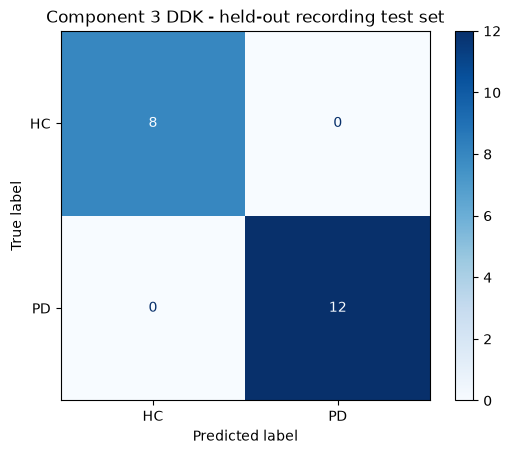

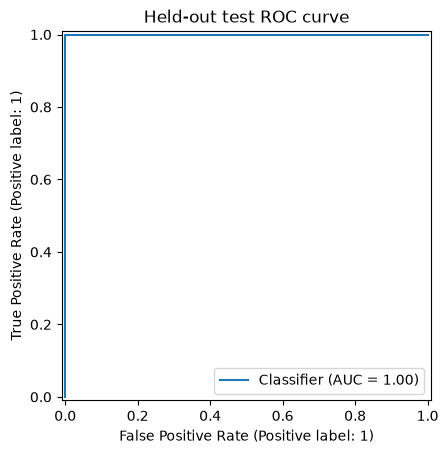

Training and CV results are not held-out test performance.


In [12]:
def evaluate_model(model, X_eval, y_eval, participant_count, label):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1] if hasattr(model, "predict_proba") else None
    cm = confusion_matrix(y_eval, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    precision, recall, f1, support = precision_recall_fscore_support(y_eval, pred, labels=[0, 1], zero_division=0)
    auc = float(roc_auc_score(y_eval, prob)) if prob is not None and y_eval.nunique() == 2 else None
    return {
        "evaluation": label, "participants": int(participant_count), "recordings": int(len(y_eval)),
        "accuracy": float(accuracy_score(y_eval, pred)), "precision_PD": float(precision[1]),
        "sensitivity_recall_PD": float(recall[1]), "specificity_HC": float(tn / (tn + fp)) if tn + fp else None,
        "f1_PD": float(f1[1]), "roc_auc": auc, "confusion_matrix_hc_pd": cm.tolist(),
        "classification_report": classification_report(y_eval, pred, labels=[0, 1], target_names=["HC", "PD"], output_dict=True, zero_division=0),
    }, pred, prob, cm

# Predeclared before looking at held-out predictions: average available D1/D2
# PD probabilities per participant; use the sole available task when one is missing.
def aggregate_participant_predictions(frame, probabilities, predictions):
    scored = frame[["participant_id", "label", "task"]].copy()
    scored["probability_pd"] = probabilities
    scored["recording_prediction"] = predictions
    rows = []
    for participant_id, group in scored.groupby("participant_id", sort=True):
        tasks = set(group["task"])
        rows.append({
            "participant_id": participant_id,
            "label": int(group["label"].iloc[0]),
            "probability_pd": float(group["probability_pd"].mean()),
            "prediction": int(group["probability_pd"].mean() >= 0.5),
            "tasks_present": "+".join(sorted(tasks)),
            "missing_task": "none" if tasks == {"D1", "D2"} else ("D2" if "D2" not in tasks else "D1"),
        })
    return pd.DataFrame(rows)

test_metrics, y_pred, y_prob, test_cm = evaluate_model(primary_model, X_test, y_test, len(test_participants), "held_out_test_recording")
participant_test_df = aggregate_participant_predictions(test_df, y_prob, y_pred)
participant_cm = confusion_matrix(participant_test_df["label"], participant_test_df["prediction"], labels=[0, 1])
participant_test_metrics, _, _, _ = evaluate_model(
    primary_model,
    participant_test_df[["label"]].rename(columns={"label": "feature_placeholder"}),
    participant_test_df["label"],
    len(participant_test_df),
    "held_out_test_participant",
) if False else (None, None, None, None)
participant_precision, participant_recall, participant_f1, _ = precision_recall_fscore_support(
    participant_test_df["label"], participant_test_df["prediction"], labels=[0, 1], zero_division=0
)
tn, fp, fn, tp = participant_cm.ravel()
participant_auc = float(roc_auc_score(participant_test_df["label"], participant_test_df["probability_pd"])) if participant_test_df["label"].nunique() == 2 else None
participant_metrics = {
    "evaluation": "held_out_test_participant",
    "participants": int(len(participant_test_df)),
    "recordings": int(len(test_df)),
    "accuracy": float(accuracy_score(participant_test_df["label"], participant_test_df["prediction"])),
    "precision_PD": float(participant_precision[1]),
    "sensitivity_recall_PD": float(participant_recall[1]),
    "specificity_HC": float(tn / (tn + fp)) if tn + fp else None,
    "f1_PD": float(participant_f1[1]),
    "roc_auc": participant_auc,
    "confusion_matrix_hc_pd": participant_cm.tolist(),
    "missing_task_participants": int((participant_test_df["missing_task"] != "none").sum()),
}
print("Declared aggregation: mean available D1/D2 PD probabilities; one-task participants use the available task.")
display(pd.DataFrame([test_metrics, participant_metrics])[['evaluation', 'participants', 'recordings', 'accuracy', 'precision_PD', 'sensitivity_recall_PD', 'specificity_HC', 'f1_PD', 'roc_auc']])
print("Missing-task test participants:", participant_metrics["missing_task_participants"])
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=["HC", "PD"], zero_division=0))
ConfusionMatrixDisplay(test_cm, display_labels=["HC", "PD"]).plot(cmap="Blues")
plt.title("Component 3 DDK - held-out recording test set")
plt.show()
if y_test.nunique() == 2 and y_prob is not None:
    RocCurveDisplay.from_predictions(y_test, y_prob)
    plt.title("Held-out test ROC curve")
    plt.show()
print("Training and CV results are not held-out test performance.")

## 9. Final held-out test evaluation

The following metrics are computed once on untouched test participants.
Specificity is the HC true-negative rate. ROC-AUC is reported only when both
test classes are present and probabilities are available. These are not
cross-validation or training metrics.

In [13]:
def evaluate_task(task_name):
    tr = train_df[train_df["task"] == task_name]
    te = test_df[test_df["task"] == task_name]
    if tr["label"].nunique() < 2 or te["label"].nunique() < 2:
        return {"task": task_name, "status": "skipped: training or test subset lacks both classes", "train_recordings": len(tr), "test_recordings": len(te), "test_participants": te["participant_id"].nunique()}
    model = RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, class_weight="balanced")
    model.fit(tr[FEATURE_NAMES], tr["label"])
    pred = model.predict(te[FEATURE_NAMES])
    prob = model.predict_proba(te[FEATURE_NAMES])[:, 1]
    result, _, _, _ = evaluate_model(model, te[FEATURE_NAMES], te["label"], te["participant_id"].nunique(), task_name)
    return {"task": task_name, "status": "evaluated", "train_recordings": len(tr), "test_recordings": len(te), "test_participants": te["participant_id"].nunique(), **{k: result[k] for k in ["accuracy", "precision_PD", "sensitivity_recall_PD", "specificity_HC", "f1_PD", "roc_auc", "confusion_matrix_hc_pd"]}}
task_results = [evaluate_task(task) for task in ["D1", "D2"]]
display(pd.DataFrame(task_results))

,task,status,train_recordings,test_recordings,test_participants,accuracy,precision_PD,sensitivity_recall_PD,specificity_HC,f1_PD,roc_auc,confusion_matrix_hc_pd
0,D1,evaluated,40,10,10,1.0,1.0,1.0,1.0,1.0,1.0,"[[4, 0], [0, 6]]"
1,D2,evaluated,40,10,10,1.0,1.0,1.0,1.0,1.0,1.0,"[[4, 0], [0, 6]]"


## 11. Save outputs

This is the notebook's single artifact-saving section. Each successful run overwrites only the four current Component 3 outputs below; it does not delete or rename unrelated files. The model bundle preserves the keys required by `component3_ddk/predict.py`.

In [14]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Stable latest-run paths. Only these specific artifacts are overwritten.
feature_output = RESULTS_DIR / "italian_pvs_ddk_features.csv"
split_output = RESULTS_DIR / "ddk_participant_split.csv"
metrics_output = RESULTS_DIR / "ddk_heldout_metrics.json"
model_output = MODELS_DIR / "component3_ddk_ddk_rf.joblib"

analysis_df.to_csv(feature_output, index=False)
split_table = participant_table.copy()
split_table["split"] = split_table["participant_id"].map(
    lambda value: "train" if value in train_participants else "test"
)
split_table.to_csv(split_output, index=False)

joblib.dump(
    {
        "model": primary_model,
        "feature_names": FEATURE_NAMES,
        "training_participants": sorted(train_participants),
        "random_state": RANDOM_STATE,
        "evaluation_note": "Fitted on training participants only; held-out test evaluated once.",
    },
    model_output,
)

all_metrics = {
    "component": "component3_ddk",
    "dataset_root": str(DATASET_ROOT),
    "participant_id_rule": identity_review["id_rule"],
    "identity_review": identity_review,
    "random_state": RANDOM_STATE,
    "test_size_requested": TEST_SIZE,
    "n_participants_total": int(participant_table["participant_id"].nunique()),
    "n_participants_train": len(train_participants),
    "n_participants_test": len(test_participants),
    "n_recordings_train": len(train_df),
    "n_recordings_test": len(test_df),
    "participant_overlap": sorted(train_participants & test_participants),
    "training_only_repeated_cv": training_cv_summary,
    "held_out_recording_metrics": test_metrics,
    "held_out_participant_metrics": participant_metrics,
    "task_metrics": task_results,
    "feature_names": FEATURE_NAMES,
    "personal_recordings_used": False,
    "duplicate_sha256_rows": int(len(duplicate_hashes)),
}
with metrics_output.open("w", encoding="utf-8") as handle:
    json.dump(all_metrics, handle, indent=2, allow_nan=False)

print("Feature table:", feature_output)
print("Participant split:", split_output)
print("Held-out metrics:", metrics_output)
print("Training-only model bundle:", model_output)


Feature table: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\italian_pvs_ddk_features.csv
Participant split: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\ddk_participant_split.csv
Held-out metrics: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\ddk_heldout_metrics.json
Training-only model bundle: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\models\component3_ddk_ddk_rf.joblib


## 12. Results, limitations, and conclusion

The earlier approximately 99% figure must not be treated as a held-out result unless it came from a participant-disjoint test set. This notebook distinguishes training-only repeated grouped CV from the single held-out test evaluation and reports both recording-level and participant-level aggregation. The dataset is small, so estimates are uncertain; repeated participant-level validation and external testing remain appropriate. Official spreadsheet files are present, but no verified cross-range participant key was established from the local metadata inventory, so structural IDs are conservative and identity uncertainty remains. Personal recordings under `data/personal_ddk/` are intentionally not discovered or used; any future use must be inference-only after training.